# 02: Statistical Exploratory Data Analysis
***
**Author:** Zain Zabidi
**Date:** February 2026

**Objective:** To perform a rigorous statistical analysis of the processed Census data, identifying correlations, testing geographical hypotheses, and detecting spatial clustering of housing stress across Western Australia.

## 1. Setup and Data Loading
In this section, we initialise our environment and load the datasets created in the previous notebook. We primarily use the GeoPackage (`.gpkg`) file because it contains both our engineered numerical features and the spatial geometries required for our mapping and autocorrelation tests.

### 1.1 Import Libraries
We begin by importing the necessary libraries for our analysis. This includes `scipy.stats` for our hypothesis testing and `seaborn/matplotlib` for visualising our data distributions.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Set plotting style for consistency
plt.style.use('ggplot')
sns.set_palette("viridis")

# Path configuration
PROCESSED_DATA_PATH = '../data/processed/'

### 1.2 Load Processed Data
Next, we load the spatial dataset we exported at the end of Notebook 01. Loading the `GeoPackage` into a GeoDataFrame allows us to access all 600+ census variables alongside their corresponding geographical boundaries for Western Australia.

In [2]:
# Load the spatial dataset
geo_path = os.path.join(PROCESSED_DATA_PATH, 'wa_census_spatial_2021.gpkg')
df = gpd.read_file(geo_path)

# Quick check of the dataframe structure to ensure all records imported correctly
print(f"Dataset loaded with {df.shape[0]} suburbs and {df.shape[1]} columns.")
display(df[['SAL_NAME21', 'avg_weekly_income', 'housing_stress_index']].head())

Dataset loaded with 1699 suburbs and 659 columns.


,SAL_NAME21,avg_weekly_income,housing_stress_index
0,Abba River,2946.107143,23.692464
1,Abbey,1830.418860,22.783521
2,Acton Park (WA),1320.258621,35.945114
3,Adamsvale,4800.000000,0.000000
4,Ajana,449.500000,0.000000


## 2. Univariate Analysis

In this section, we examine the distribution of our primary variables. Before we can test how different variables relate to each other, we need to understand the "shape" of our data. We will look for skewness, outliers, and the general spread of housing stress across the state.

### 2.1 Distribution of Housing Stress

We start by visualising the `housing_stress_index`. This index represents the percentage of household income spent on rent or mortgage repayments. By using a histogram and a boxplot together, we can identify the central tendency and see how many suburbs are experiencing extreme levels of financial pressure.

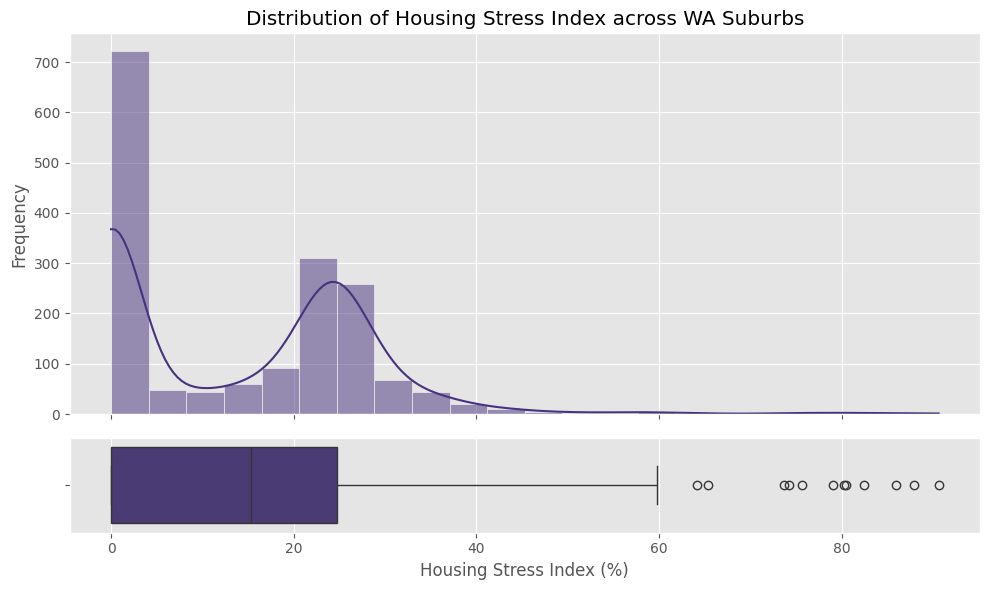

count    1699.000000
mean       14.092720
std        14.212830
min         0.000000
25%         0.000000
50%        15.310382
75%        24.714447
max        90.591874
Name: housing_stress_index, dtype: float64


In [3]:
# Create a figure with two subplots: a histogram and a boxplot
fig, (ax_hist, ax_box) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.8, .2)}, figsize=(10, 6))

# Plot the histogram to show the frequency of stress levels
sns.histplot(data=df, x='housing_stress_index', kde=True, ax=ax_hist)
ax_hist.set_title('Distribution of Housing Stress Index across WA Suburbs')
ax_hist.set_ylabel('Frequency')

# Plot the boxplot to highlight outliers
sns.boxplot(data=df, x='housing_stress_index', ax=ax_box)
ax_box.set_xlabel('Housing Stress Index (%)')

plt.tight_layout()
plt.show()

# Calculate descriptive statistics for a numerical summary
print(df['housing_stress_index'].describe())

### 2.2 Observations on Housing Stress

Based on the visual and numerical summary, we can make the following observations:

* **Bimodal Distribution:** The data shows two distinct peaks. The peak at `0%` likely represents suburbs where households own their homes outright or data is suppressed. The second peak, around `20-25%`, represents the typical experience for active renters and mortgage holders.
* **Significant Outliers:** The boxplot identifies several `extreme outliers` with stress levels exceeding `60%`, reaching a maximum of `90.6%`. These suburbs are under intense financial pressure compared to the state average.
* **Skewness & Central Tendency:** While the `mean` is `14.09%`, the `median` of `15.31%` shows that once we move past the zero-value suburbs, the distribution leans toward the higher end of the scale.

### 2.3 Distribution of Income and Mining Concentration

To understand the economic drivers behind housing stress, we examine the spread of wealth and industrial specialisation. `Average Weekly Income` tells us about the financial capacity of a suburb, while the `Mining Concentration Ratio` identifies areas heavily dependent on the resources sector. 

Observing these distributions helps us decide if we need to apply any transformations (like log scaling) before moving into regression modelling.

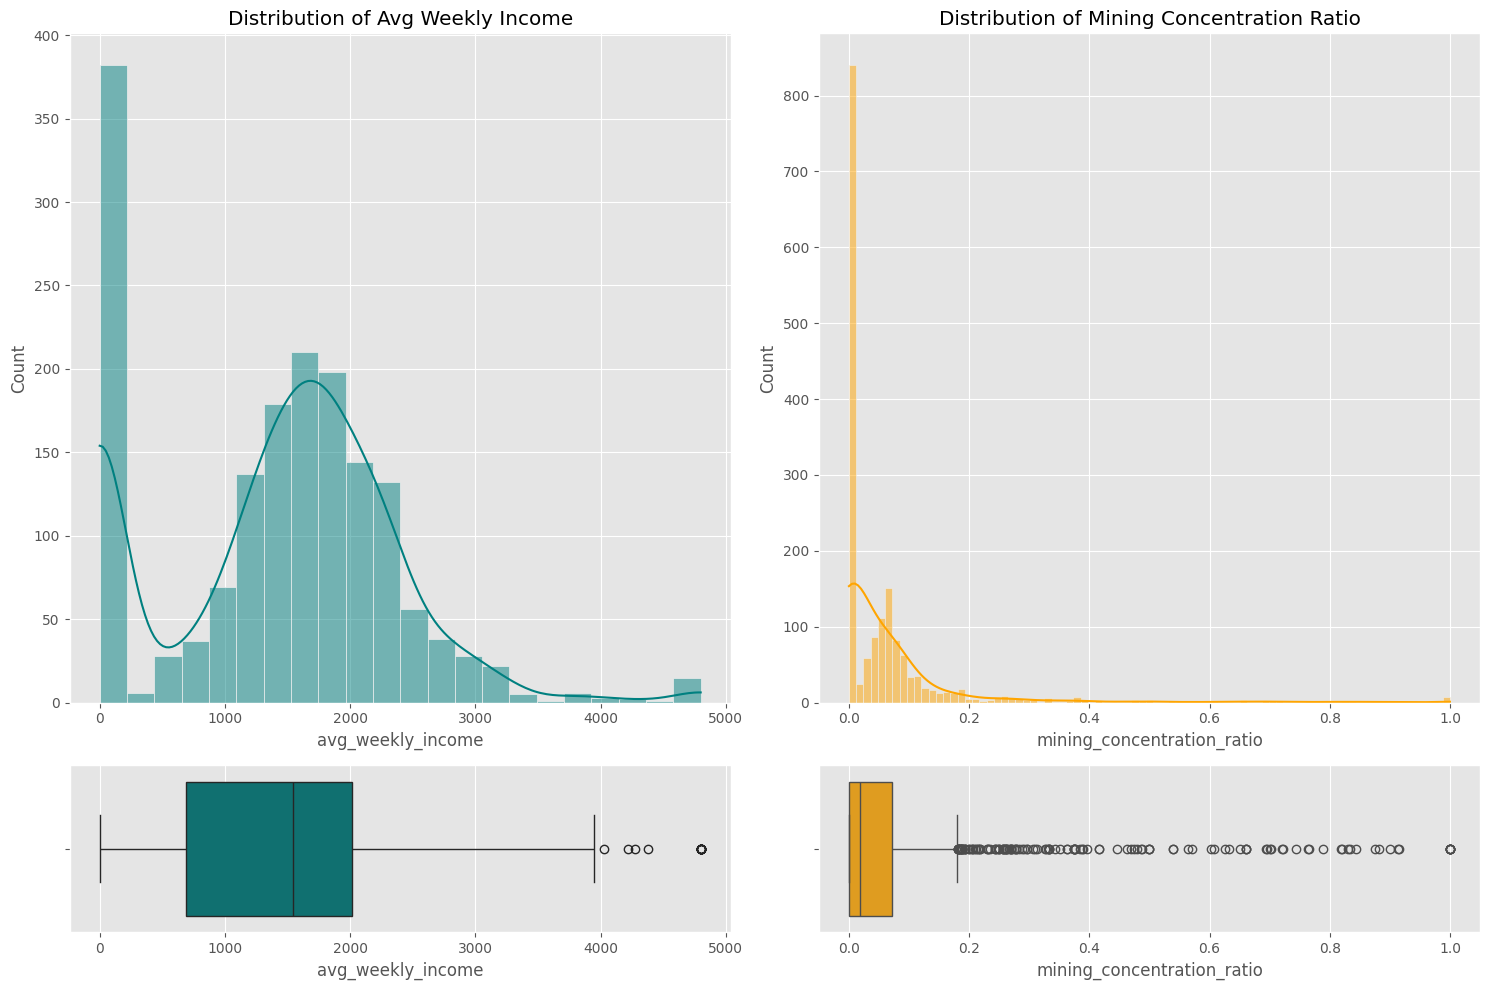

,avg_weekly_income,mining_concentration_ratio
count,1699.000000,1699.000000
mean,1399.908593,0.065469
std,963.589463,0.134410
min,0.000000,0.000000
25%,689.325000,0.000000
50%,1540.831568,0.018546
75%,2014.703792,0.072401
max,4800.000000,1.000000


In [4]:
# Set up grid for two sets of plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"height_ratios": (.8, .2)})

# Plot 1: Average Weekly Income
sns.histplot(data=df, x='avg_weekly_income', kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Avg Weekly Income')
sns.boxplot(data=df, x='avg_weekly_income', ax=axes[1, 0], color='teal')

# Plot 2: Mining Concentration Ratio
sns.histplot(data=df, x='mining_concentration_ratio', kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Distribution of Mining Concentration Ratio')
sns.boxplot(data=df, x='mining_concentration_ratio', ax=axes[1, 1], color='orange')

plt.tight_layout()
plt.show()

# Display summary statistics for both
display(df[['avg_weekly_income', 'mining_concentration_ratio']].describe())

### 2.4 Observations on Economic Drivers

Based on the visual and numerical summary, we can refine our insights:

* **Bimodal Income:** The `avg_weekly_income` follows a bimodal pattern similar to housing stress. Beyond the initial spike at `$0`, the data is normally distributed around a median of `$1,540`, with "prestige" outliers reaching up to `$4,800`.
* **Extreme Mining Specialisation:** The `mining_concentration_ratio` is intensely right-skewed. While the `median` suburb has less than `2%` mining employment, the outliers reach a staggering `100% (1.0)`. This highlights the extreme industrial specialisation in certain WA regions.
* **Structural Zeros:** The consistent presence of `0` values across income, mining, and stress confirms that our dataset includes non-residential or industrially-zoned areas (like `Adamsvale` or `Ajana`) which we may need to handle before regression modelling.

## 3. Correlation Analysis

In this section, we transition from examining variables in isolation to identifying relationships between them. We want to quantify how strongly our predictors associate with housing stress.
### 3.1 Feature Correlation Heatmap
We use a Pearson correlation matrix to identify the linear strength between variables. This helps us spot potential multicollinearity and prioritise features for our regression model.

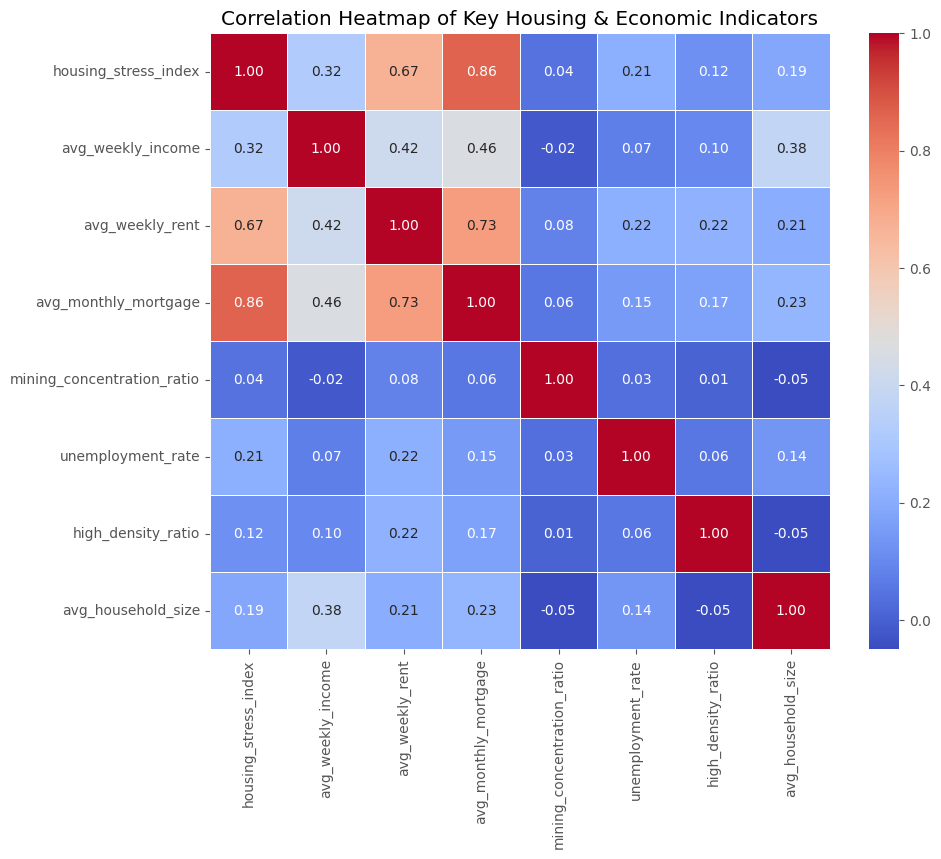

In [6]:
# Select a subset of key features for correlation matrix
core_features = [
    'housing_stress_index', 'avg_weekly_income', 'avg_weekly_rent', 
    'avg_monthly_mortgage', 'mining_concentration_ratio', 
    'unemployment_rate', 'high_density_ratio', 'avg_household_size'
]

# Calculate the Pearson correlation matrix
corr_matrix = df[core_features].corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Key Housing & Economic Indicators')
plt.show()

## 3. Correlation Analysis
In this section, we transition from examining variables in isolation to identifying relationships between them. Our goal is to quantify how strongly our predictors associate with `housing_stress_index`.

### 3.1 Feature Correlation Heatmap
We use a `Pearson correlation matrix` to identify the linear strength between variables. This helps us spot potential `multicollinearity` and prioritise features for our regression model. Key focus areas include:

* **Direct Drivers:** Identifying which costs (Rent vs. Mortgage) impact the `housing_stress_index` most significantly.
* **Redundancy Check:** Ensuring we don't use two variables that are too similar (e.g., `avg_weekly_income` vs. `avg_weekly_rent`) which could lead to `model instability`.

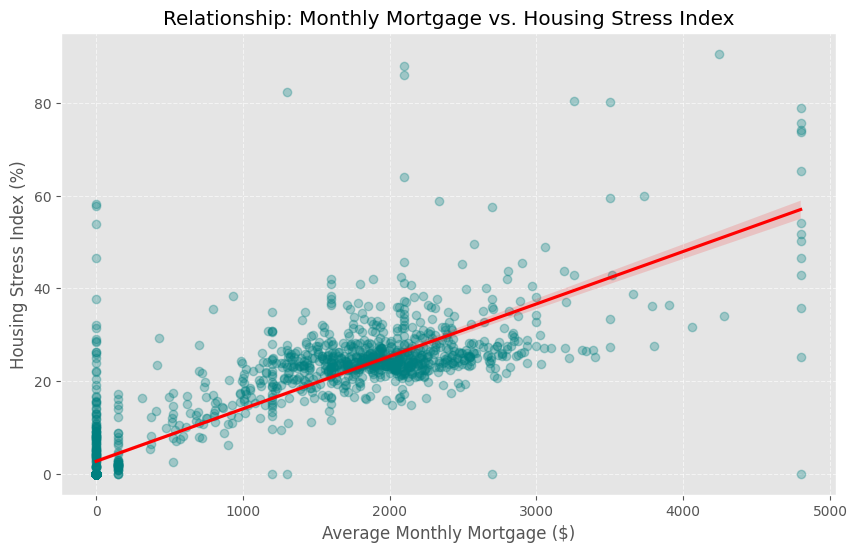

In [7]:
# Create a scatter plot to visualise the strongest correlation
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='avg_monthly_mortgage', y='housing_stress_index', 
            scatter_kws={'alpha':0.3, 'color':'teal'}, line_kws={'color':'red'})

plt.title('Relationship: Monthly Mortgage vs. Housing Stress Index')
plt.xlabel('Average Monthly Mortgage ($)')
plt.ylabel('Housing Stress Index (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3.3 Observations on Correlations and Key Relationships
By looking at the `Heatmap` and `Scatter Plot` together, we can see:

* **Top Predictors:** `avg_monthly_mortgage` (0.86) and `avg_weekly_rent` (0.67) are the strongest drivers of housing stress. The scatter plot shows a clear link: as mortgage costs go up, so does the stress index.
* **The Income Factor:** `avg_weekly_income` has a positive correlation (0.32). This sounds strange, but it is likely because high-income areas often have much larger mortgages, which increases the overall stress level.
* **Mining Impact:** The `mining_concentration_ratio` shows almost no linear relationship (0.04) on a state-wide level. This suggests that mining does not automatically equal high or low stress for everyone in WA.
* **Extreme Outliers:** The scatter plot shows some suburbs with `$0` mortgage but high stress. These are likely areas where high rental costs are the main problem, rather than home ownership costs.

## 4. Hypothesis Testing
In this section, we test if the differences between specific groups are statistically significant. We will use the `scipy.stats` library to perform an independent T-Test.

### 4.1 Defining the Groups (Mining vs. Non-Mining)
To test the impact of the resources sector, we split our data into two groups based on the `mining_concentration_ratio`. 

* **Mining-Heavy:** Suburbs in the top 25% of mining employment.
* **Non-Mining:** All other suburbs.

**Hypotheses:**
* **Null Hypothesis ($H_0$):** There is no significant difference in `housing_stress_index` between **mining-heavy suburbs** and the rest of WA.
* **Alternative Hypothesis ($H_1$):** **Mining-heavy suburbs** have a significantly different `housing_stress_index` compared to the rest of WA.

T-Statistic: 9.7519
P-Value: 6.7201e-22


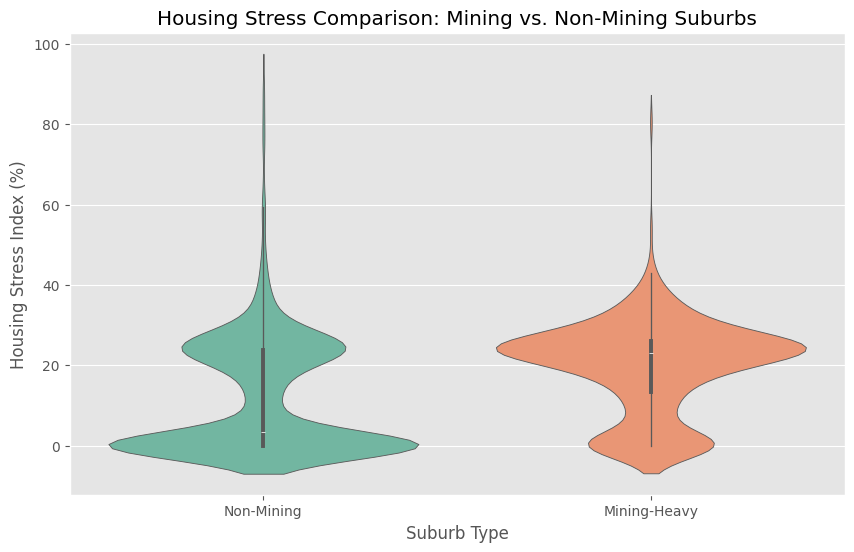

In [10]:
from scipy import stats

# Define threshold for "Mining Heavy" using the 75th percentile
threshold = df['mining_concentration_ratio'].quantile(0.75)

# Create boolean mask for groups
is_mining_heavy = df['mining_concentration_ratio'] > threshold

mining_group = df[is_mining_heavy]['housing_stress_index']
non_mining_group = df[~is_mining_heavy]['housing_stress_index']

# Perform an independent T-Test
t_stat, p_val = stats.ttest_ind(mining_group, non_mining_group, nan_policy='omit')

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_val:.4e}")

# Visualise the comparison with a violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df, 
    x=is_mining_heavy, 
    y='housing_stress_index', 
    hue=is_mining_heavy, 
    palette="Set2", 
    legend=False
)

plt.xticks([0, 1], ['Non-Mining', 'Mining-Heavy'])
plt.title('Housing Stress Comparison: Mining vs. Non-Mining Suburbs')
plt.xlabel('Suburb Type')
plt.ylabel('Housing Stress Index (%)')
plt.show()

**Quick Observations:**
* The `T-Statistic` of `9.75` and a `P-Value` near zero indicate a statistically significant difference in housing stress between the two groups.
* The violin plot for `Mining-Heavy` suburbs shows a much "fatter" section around the 25% stress mark compared to `Non-Mining` suburbs, which have a larger concentration of low-stress (0%) areas.

### 4.2 Comparing Income Levels (The "Wealth Shield" Test)
We now test whether `Mining-Heavy` suburbs actually have higher average incomes to compensate for their housing costs. This helps us understand if the stress identified in Section 4.1 is driven by high costs alone or by a lack of comparative income.

**Hypotheses:**
* **Null Hypothesis ($H_0$):** There is no significant difference in `avg_weekly_income` between mining-heavy suburbs and the rest of WA.
* **Alternative Hypothesis ($H_1$):** Mining-heavy suburbs have a significantly different (likely higher) `avg_weekly_income` compared to the rest of WA.

Income T-Statistic: 5.3456
Income P-Value: 1.0233e-07


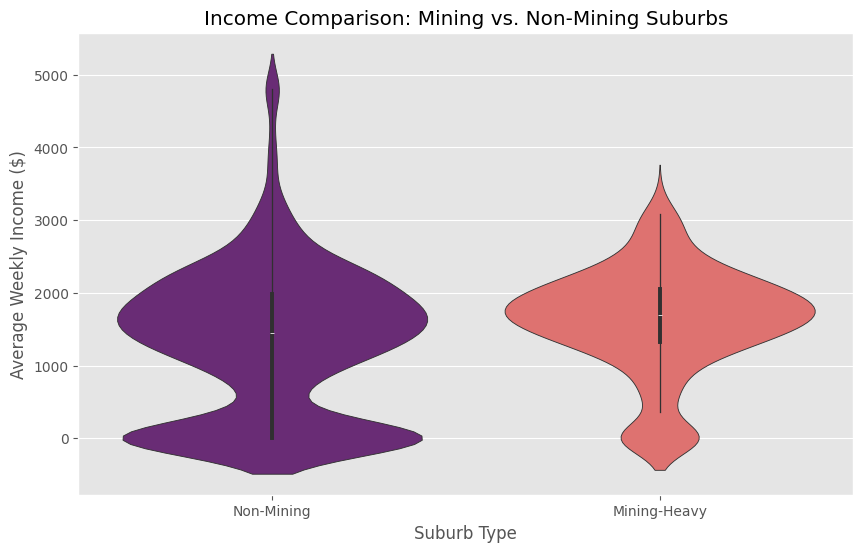

In [11]:
# We use the same 'is_mining_heavy' mask from the previous step
mining_income = df[is_mining_heavy]['avg_weekly_income']
non_mining_income = df[~is_mining_heavy]['avg_weekly_income']

# Perform the independent T-Test for Income
t_stat_inc, p_val_inc = stats.ttest_ind(mining_income, non_mining_income, nan_policy='omit')

print(f"Income T-Statistic: {t_stat_inc:.4f}")
print(f"Income P-Value: {p_val_inc:.4e}")

# Visualise the income distribution comparison
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df, 
    x=is_mining_heavy, 
    y='avg_weekly_income', 
    hue=is_mining_heavy, 
    palette="magma", 
    legend=False
)

plt.xticks([0, 1], ['Non-Mining', 'Mining-Heavy'])
plt.title('Income Comparison: Mining vs. Non-Mining Suburbs')
plt.xlabel('Suburb Type')
plt.ylabel('Average Weekly Income ($)')
plt.show()

**Quick Observations:**
* The `P-Value` of `1.02e-07` confirms that the income difference is statistically significant, but the lower `T-Statistic` (5.34) compared to the stress test suggests the "income gap" is less pronounced than the "stress gap."
* The `Mining-Heavy` violin shows a higher "floor" for income, with very few suburbs falling below the $1,000/week mark compared to the rest of the state.

### 4.3 Section Summary and Hypothesis Results
After performing our statistical tests, we have reached the following conclusions for this section:
* **Housing Stress Result:** With a p-value of `6.72e-22`, we **reject the Null Hypothesis ($H_0$)**. There is a statistically significant difference in housing stress between mining-heavy suburbs and the rest of WA.
* **Average Income Result:** With a p-value of `1.02e-07`, we also **reject the Null Hypothesis ($H_0$)**. This confirms that mining-heavy suburbs earn significantly more on average.
* **The "Stress vs. Wage" Gap:** While both results are significant, the `T-Statistic` for housing stress (9.75) is much higher than for income (5.34). 
* **Final Takeaway:** This proves that even though mining areas have higher incomes, it is not enough to balance out the higher costs. Residents in these areas still face significantly more housing stress than the rest of the state.